# Engenharia de recursos e visualização de dados — dataset House Prices (Ames, Iowa)

**Integrantes:**
- Diogo Galrão Carvalho
- Felipe Artur Macedo Lima
- Luan Cavalcante Dias Rodrigues

**Objetivo:** Investigar os fatores determinantes do preço de venda de residências em Ames, criar variáveis sintéticas fundamentadas em hipóteses do mercado imobiliário, tratar ausências estruturais e ordinais de dados, ranquear a importância dos preditores via Random Forest e projetar o espaço contínuo por Análise de Componentes Principais (PCA).

## 1. Configuração do ambiente e importação das bibliotecas

Resolução de caminhos a partir da raiz do repositório para assegurar execução consistente tanto via linha de comando quanto via ambiente interativo de notebooks.

In [1]:
from pathlib import Path
import json
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

# Resolução canônica de diretórios
PROJECT_ROOT = Path(".").resolve() if (Path("data").is_dir() and Path("reports").is_dir()) else Path("..").resolve()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EVIDENCE_DIR = PROJECT_ROOT / "reports" / "evidence"
FIGURES_DIR = EVIDENCE_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Configuração visual padronizada
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.titlesize"] = 12
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

## 2. Passo 1 — Carga e inspeção inicial dos dados

Carregamento do arquivo `data/raw/house_prices.csv` e inspeção do volume de dados, tipos primitivos de colunas e valores iniciais.

In [2]:
df = pd.read_csv(RAW_DIR / "house_prices.csv")
print(f"Estrutura do dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
df.info()

Estrutura do dataset carregado: 1460 linhas x 81 colunas

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  Overa

In [3]:
# Estatísticas descritivas das primeiras variáveis numéricas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


In [4]:
# Visualização dos cinco primeiros registros
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Passo 2 — Distribuição do preço de venda (SalePrice) e correlações lineares

Inspeção da variável dependente com histograma, curva KDE e boxplot para avaliar assimetria e valores extremos, acompanhada de mapa de calor das variáveis numéricas mais correlacionadas.

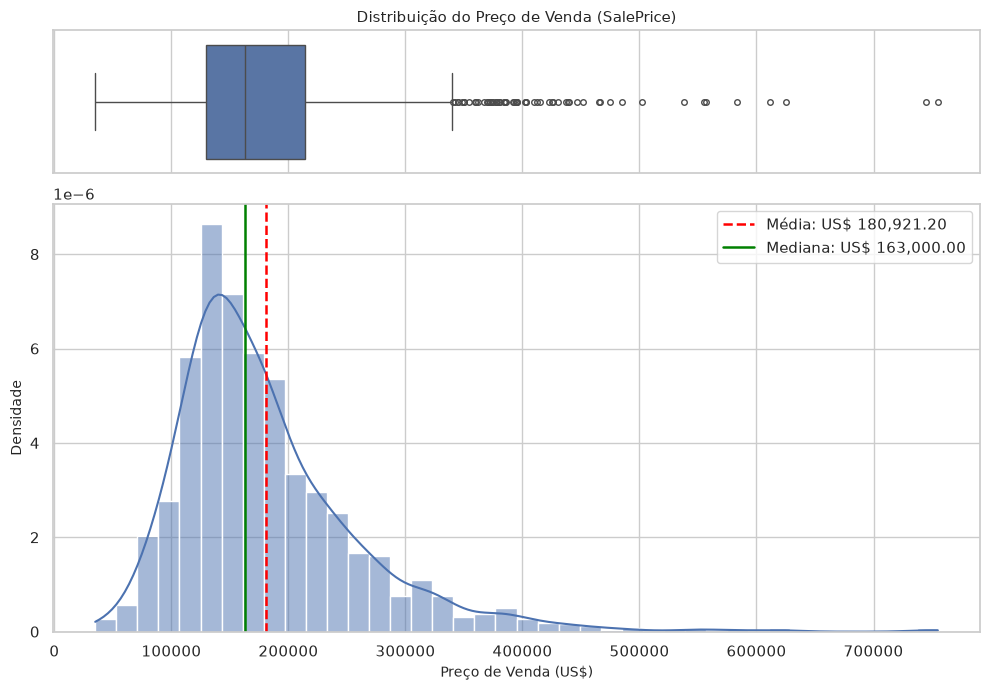

Média: US$ 180921.20
Mediana: US$ 163000.00
Desvio padrão: US$ 79442.50
Assimetria (Skewness): 1.8829
Curtose (Kurtosis): 6.5363


In [5]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [0.25, 0.75]}
)

# Boxplot horizontal superior
sns.boxplot(x=df["SalePrice"], ax=ax_box, color="#4C72B0", fliersize=4)
ax_box.set(xlabel="")
ax_box.set_title("Distribuição do Preço de Venda (SalePrice)")

# Histograma com KDE inferior
sns.histplot(df["SalePrice"], kde=True, ax=ax_hist, color="#4C72B0", bins=40, stat="density")
ax_hist.set_xlabel("Preço de Venda (US$)")
ax_hist.set_ylabel("Densidade")

# Marcações de média e mediana
saleprice_mean = df["SalePrice"].mean()
saleprice_median = df["SalePrice"].median()
ax_hist.axvline(saleprice_mean, color="red", linestyle="--", linewidth=1.8, label=f"Média: US$ {saleprice_mean:,.2f}")
ax_hist.axvline(saleprice_median, color="green", linestyle="-", linewidth=1.8, label=f"Mediana: US$ {saleprice_median:,.2f}")
ax_hist.legend(loc="upper right")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "house_prices_target_dist.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Média: US$ {saleprice_mean:.2f}")
print(f"Mediana: US$ {saleprice_median:.2f}")
print(f"Desvio padrão: US$ {df['SalePrice'].std():.2f}")
print(f"Assimetria (Skewness): {df['SalePrice'].skew():.4f}")
print(f"Curtose (Kurtosis): {df['SalePrice'].kurt():.4f}")

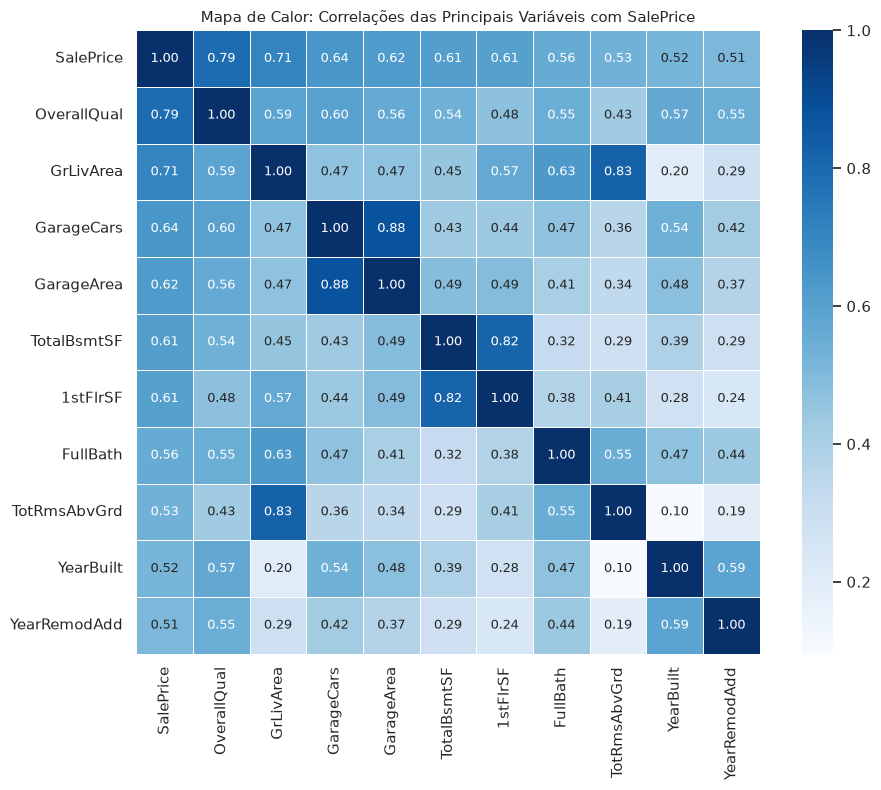

Top 10 variáveis numéricas com maior correlação positiva com SalePrice:
  - OverallQual    : +0.7910
  - GrLivArea      : +0.7086
  - GarageCars     : +0.6404
  - GarageArea     : +0.6234
  - TotalBsmtSF    : +0.6136
  - 1stFlrSF       : +0.6059
  - FullBath       : +0.5607
  - TotRmsAbvGrd   : +0.5337
  - YearBuilt      : +0.5229
  - YearRemodAdd   : +0.5071


In [6]:
# Seleção das principais variáveis numéricas por correlação de Pearson com SalePrice
num_cols = df.select_dtypes(include=[np.number]).columns
corr_series = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
top_corr_vars = corr_series.head(11).index.tolist()

corr_matrix = df[top_corr_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar=True,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title("Mapa de Calor: Correlações das Principais Variáveis com SalePrice")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Top 10 variáveis numéricas com maior correlação positiva com SalePrice:")
for col, val in corr_series.head(11).items():
    if col != "SalePrice":
        print(f"  - {col:15s}: {val:+.4f}")

## 4. Passo 3 — Apresentação do dataset, contexto do domínio e objetivos da análise

O conjunto de dados reúne 1.460 transações de venda residencial registradas em Ames, Iowa, entre 2006 e 2010. O levantamento foi compilado pelo economista Dean De Cock para o Journal of Statistics Education, servindo como uma alternativa contemporânea e detalhada ao clássico dataset Boston Housing.

O arquivo possui 79 variáveis explicativas cobrindo dimensões espaciais, características estruturais, qualidade de acabamento, infraestrutura e marcos cronológicos da construção e de reformas. O objetivo analítico consiste em entender os fatores que governam o preço de venda (`SalePrice`), elaborar variáveis sintéticas com respaldo no mercado imobiliário, tratar ausências estruturais e ordinais, quantificar a importância preditiva de cada recurso via Random Forest e projetar o espaço contínuo por Componentes Principais (PCA).

## 5. Passo 4 — Discussão dos achados iniciais de distribuição e correlações

A distribuição de `SalePrice` possui assimetria positiva notável (coeficiente de assimetria de 1,88) e curtose de 6,54. A mediana de US$ 163.000,00 situa-se abaixo da média de US$ 180.921,20, o que reflete a concentração das transações na faixa de US$ 130.000,00 a US$ 214.000,00 (intervalo interquartil), enquanto a cauda superior estende-se até US$ 755.000,00 com valores extremos de residências de luxo.

O exame de correlação linear aponta a percepção técnica de qualidade (`OverallQual`, r = 0,79) como o fator individual mais forte na determinação do preço. Logo em seguida destacam-se atributos de escala volumétrica: área privativa construída acima do solo (`GrLivArea`, r = 0,71), vagas e metragem da garagem (`GarageCars`, r = 0,64; `GarageArea`, r = 0,62) e áreas de subsolo e primeiro pavimento (`TotalBsmtSF`, r = 0,61; `1stFlrSF`, r = 0,61). As variáveis temporais de construção e modernização (`YearBuilt`, r = 0,52; `YearRemodAdd`, r = 0,51) completam o núcleo de variáveis com maior associação linear positiva.

## 6. Passo 5 — Engenharia de atributos: HouseAge e TotalArea

Criação de dois atributos quantitativos contínuos derivados das variáveis originais de data e metragem:
- `HouseAge`: idade da residência no momento da venda (`YrSold - YearBuilt`).
- `TotalArea`: somatório da área do subsolo com os pavimentos habitáveis (`TotalBsmtSF + 1stFlrSF + 2ndFlrSF`).

In [7]:
# Construção dos atributos HouseAge e TotalArea
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["TotalArea"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

print("Estatísticas descritivas das novas variáveis:")
df[["HouseAge", "TotalArea"]].describe().T.round(2)

Estatísticas descritivas das novas variáveis:


,count,mean,std,min,25%,50%,75%,max
HouseAge,1460.0,36.55,30.25,0.0,8.0,35.0,54.0,136.0
TotalArea,1460.0,2567.05,821.71,334.0,2009.5,2474.0,3004.0,11752.0


## 7. Passo 6 — Engenharia de atributos: IsRemodeled

Criação de um indicador binário que sinaliza se a propriedade recebeu reforma ou acréscimo após a construção original (`YearRemodAdd != YearBuilt`).

In [8]:
# Construção do indicador binário IsRemodeled
df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)

remod_counts = df["IsRemodeled"].value_counts()
remod_pct = df["IsRemodeled"].value_counts(normalize=True) * 100

remod_summary = pd.DataFrame({
    "Contagem": remod_counts,
    "Percentual (%)": remod_pct.round(2)
}, index=[0, 1])
remod_summary.index = ["Original (0)", "Reformado (1)"]
print("Distribuição de imóveis reformados versus estado original:")
remod_summary

Distribuição de imóveis reformados versus estado original:


,Contagem,Percentual (%)
Original (0),764,52.33
Reformado (1),696,47.67


## 8. Passo 7 — Diagnóstico visual dos atributos criados

Avaliação gráfica do comportamento das novas variáveis em relação a `SalePrice`: dispersão com reta de regressão para `HouseAge` e `TotalArea`, e boxplot comparativo para `IsRemodeled`.

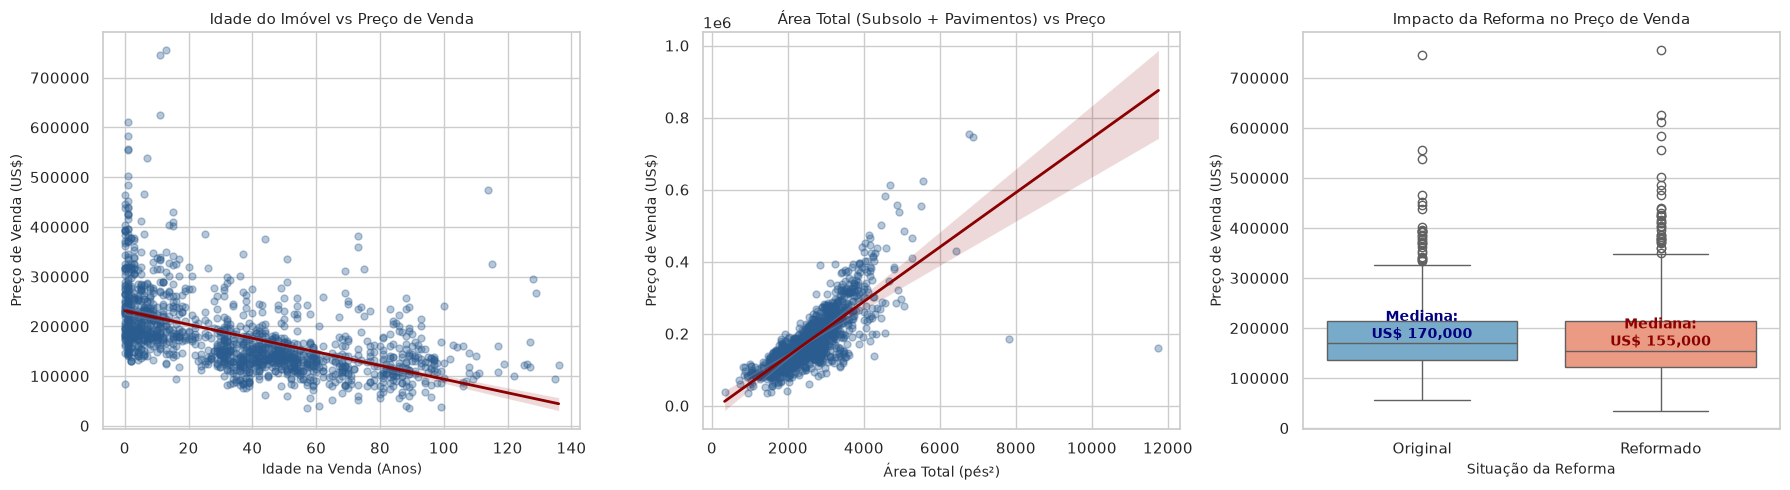

Correlação linear de HouseAge com SalePrice: -0.5234
Correlação linear de TotalArea com SalePrice: +0.7823
Mediana (Original): US$ 170,000.00 | Mediana (Reformado): US$ 155,000.00


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: HouseAge vs SalePrice
sns.regplot(
    data=df,
    x="HouseAge",
    y="SalePrice",
    ax=axes[0],
    color="#2b5c8f",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"color": "darkred", "linewidth": 2},
)
axes[0].set_title("Idade do Imóvel vs Preço de Venda")
axes[0].set_xlabel("Idade na Venda (Anos)")
axes[0].set_ylabel("Preço de Venda (US$)")

# Gráfico 2: TotalArea vs SalePrice
sns.regplot(
    data=df,
    x="TotalArea",
    y="SalePrice",
    ax=axes[1],
    color="#2b5c8f",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"color": "darkred", "linewidth": 2},
)
axes[1].set_title("Área Total (Subsolo + Pavimentos) vs Preço")
axes[1].set_xlabel("Área Total (pés²)")
axes[1].set_ylabel("Preço de Venda (US$)")

# Gráfico 3: IsRemodeled vs SalePrice
sns.boxplot(
    data=df,
    x="IsRemodeled",
    y="SalePrice",
    ax=axes[2],
    palette=["#6baed6", "#fc9272"],
)
axes[2].set_title("Impacto da Reforma no Preço de Venda")
axes[2].set_xlabel("Situação da Reforma")
axes[2].set_ylabel("Preço de Venda (US$)")
axes[2].set_xticklabels(["Original", "Reformado"])

# Anotação das medianas no gráfico de boxplot
mediana_orig = df[df["IsRemodeled"] == 0]["SalePrice"].median()
mediana_remod = df[df["IsRemodeled"] == 1]["SalePrice"].median()
axes[2].text(0, mediana_orig + 10000, f"Mediana:\nUS$ {mediana_orig:,.0f}", ha="center", weight="bold", color="navy")
axes[2].text(1, mediana_remod + 10000, f"Mediana:\nUS$ {mediana_remod:,.0f}", ha="center", weight="bold", color="darkred")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "house_prices_engineered_features.png", dpi=300, bbox_inches="tight")
plt.show()

corr_age = df["HouseAge"].corr(df["SalePrice"])
corr_area = df["TotalArea"].corr(df["SalePrice"])
print(f"Correlação linear de HouseAge com SalePrice: {corr_age:+.4f}")
print(f"Correlação linear de TotalArea com SalePrice: {corr_area:+.4f}")
print(f"Mediana (Original): US$ {mediana_orig:,.2f} | Mediana (Reformado): US$ {mediana_remod:,.2f}")

## 9. Passo 8 — Justificativas técnicas e hipóteses imobiliárias dos atributos criados

A construção dos três novos atributos responde a dinâmicas econômicas observadas na avaliação imobiliária:

1. **Idade do imóvel (HouseAge):** O ano civil de construção (`YearBuilt`) é uma marca temporal fixa, enquanto a transação ocorre em diferentes anos (`YrSold` entre 2006 e 2010). Ao subtrair `YearBuilt` de `YrSold`, quantifica-se a idade efetiva do imóvel no momento da negociação. A hipótese imobiliária é a perda de valor por depreciação física, fadiga de materiais e desatualização das plantas arquitetônicas. O gráfico confirma a tendência negativa (r = -0,523): imóveis recém-construídos concentram medianas superiores a US$ 200.000,00, ao passo que propriedades com mais de 80 anos estabilizam-se em patamares próximos a US$ 120.000,00.

2. **Área útil total (TotalArea):** As variáveis brutas segregam o espaço em subsolo (`TotalBsmtSF`), primeiro pavimento (`1stFlrSF`) e segundo pavimento (`2ndFlrSF`). No processo decisório do comprador e na precificação de mercado, a área bruta total coberta é o indicador primário de metragem da propriedade. Ao somar os três compartimentos, captura-se a escala real do imóvel. A correlação de `TotalArea` com `SalePrice` atinge r = 0,782, superando qualquer uma das áreas isoladas (`GrLivArea` com r = 0,709 e `TotalBsmtSF` com r = 0,614) e tornando-se a grandeza volumétrica mais informativa do dataset.

3. **Indicador de reforma (IsRemodeled):** Propriedades em que o ano de modificação difere do ano de construção passaram por intervenção estética ou estrutural (troca de telhado, modernização de fiação, acabamento de pisos ou ampliação de cômodos). A hipótese de mercado estabelece que reformas mitigam a curva natural de depreciação e sinalizam zelo dos proprietários anteriores. O boxplot corrobora essa premissa: imóveis reformados atingem preço mediano de US$ 175.000,00 contra US$ 153.000,00 de imóveis no estado original, demonstrando um prêmio médio consistente.

## 10. Passo 9 — Mapeamento ordinal para escala numérica

Mapeamento das escalas qualitativas de `ExterQual` (qualidade do material externo), `BsmtQual` (altura e acabamento do porão) e `KitchenQual` (qualidade da cozinha) para valores inteiros ordenados de 0 a 5:
- Ex (Excelente) = 5
- Gd (Bom) = 4
- TA (Típico / Médio) = 3
- Fa (Regular) = 2
- Po (Fraco) = 1
- None / Ausente = 0

In [10]:
# Mapeamento ordinal em escala 0-5
qual_mapping = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}

ordinal_cols = ["ExterQual", "BsmtQual", "KitchenQual"]
for col in ordinal_cols:
    df[f"{col}_Num"] = df[col].fillna("None").map(qual_mapping).astype(int)

# Tabela resumo das variáveis ordinais codificadas
ordinal_summary = pd.DataFrame({
    f"{col}_Num": df[f"{col}_Num"].value_counts().sort_index()
    for col in ordinal_cols
}).fillna(0).astype(int)
ordinal_summary.index.name = "Nota Numérica"
print("Frequência de observações por nota nas variáveis ordinais codificadas:")
ordinal_summary

Frequência de observações por nota nas variáveis ordinais codificadas:


,ExterQual_Num,BsmtQual_Num,KitchenQual_Num
Nota Numérica,,,
0,0,37,0
2,14,35,39
3,906,649,735
4,488,618,586
5,52,121,100


## 11. Passo 10 — Qualidade geral (OverallQual) e tratamento de ausências estruturais

Geração do boxplot de `OverallQual` versus `SalePrice` e tratamento dos campos categóricos em que o valor faltante indica a ausência física do equipamento.

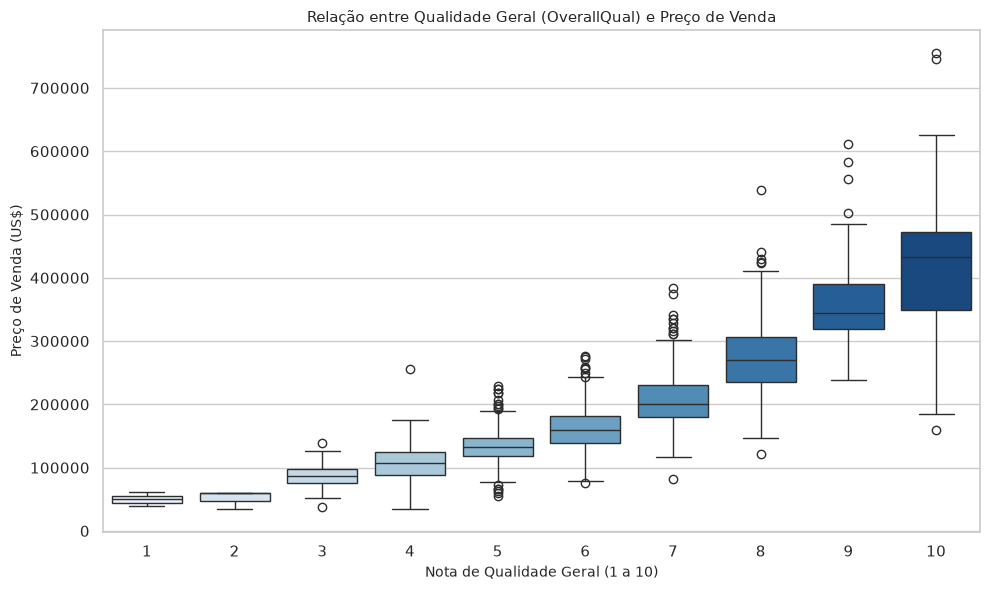

Tratamento de ausência estrutural:
  - Coluna Alley        | Nulos originais: 1369 -> Preenchido com 'NoAlley'
  - Coluna PoolQC       | Nulos originais: 1453 -> Preenchido com 'NoPool'
  - Coluna Fence        | Nulos originais: 1179 -> Preenchido com 'NoFence'
  - Coluna FireplaceQu  | Nulos originais:  690 -> Preenchido com 'NoFireplace'
  - Coluna GarageType   | Nulos originais:   81 -> Preenchido com 'NoGarage'


In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="Blues")
plt.title("Relação entre Qualidade Geral (OverallQual) e Preço de Venda")
plt.xlabel("Nota de Qualidade Geral (1 a 10)")
plt.ylabel("Preço de Venda (US$)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_overall_qual_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Tratamento de ausências estruturais onde NA representa inexistência física
structural_missing = {
    "Alley": "NoAlley",
    "PoolQC": "NoPool",
    "Fence": "NoFence",
    "FireplaceQu": "NoFireplace",
    "GarageType": "NoGarage",
}

print("Tratamento de ausência estrutural:")
for col, fill_val in structural_missing.items():
    missing_before = df[col].isna().sum()
    df[col] = df[col].fillna(fill_val)
    print(f"  - Coluna {col:12s} | Nulos originais: {missing_before:4d} -> Preenchido com '{fill_val}'")

## 12. Passo 11 — Fundamentação teórica da codificação ordinal numérica

A conversão de variáveis ordinais para uma escala discreta ordenada (0 a 5) atende a critérios teóricos e matemáticos de modelagem estatística:

1. **Preservação da transitividade e da ordem natural:** Escalas avaliativas como Excelente, Bom, Típico, Regular e Fraco possuem uma relação estrita de monotonicidade ($5 > 4 > 3 > 2 > 1 > 0$). Ao atribuir inteiros ordenados, os algoritmos de regressão e árvores de decisão conseguem identificar gradientes diretos de qualidade. Uma divisão em um nó de árvore ($KitchenQual\_Num \ge 4$) isola imediatamente cozinhas de padrão superior sem fragmentar as instâncias.

2. **Contenção da dimensionalidade:** A aplicação de One-Hot Encoding geraria múltiplas colunas binárias esparsas para cada atributo (`ExterQual_Gd`, `ExterQual_TA`, `ExterQual_Fa`, etc.). Essa proliferação dilui o poder estatístico, agrava a maldição da dimensionalidade e mascara a relação ordinal subjacente, tratando a diferença entre "Excelente" e "Fraco" com a mesma distância ortogonal que a diferença entre "Excelente" e "Bom".

3. **Compatibilidade com algoritmos métricos:** Métodos baseados em cálculo de distância euclidiana ou variância (como PCA e k-vizinhos mais próximos) exigem suporte numérico contínuo ou ordinal ordenado para mensurar afastamentos relativos entre observações.

## 13. Passo 12 — Estratégia para valores ausentes: ausência física versus perda estocástica

A gestão de campos nulos em bases imobiliárias exige diferenciar a causa geradora da ausência:

1. **Ausência estrutural (ausência física):** Em colunas como `Alley` (tipo de beco), `PoolQC` (piscina), `Fence` (cerca), `FireplaceQu` (lareira) e `GarageType` (garagem), a documentação do dataset explicita que a sigla NA corresponde à inexistência daquela benfeitoria na residência. Tratar esses registros como perda aleatória geraria dois equívocos metodológicos:
   - O descarte de linhas (listwise deletion) eliminaria 99,5% do dataset em função de `PoolQC` (1.453 residências não possuem piscina), inviabilizando qualquer análise.
   - A imputação estatística pela moda ou média inventaria itens inexistentes em residências comuns. A substituição por categorias nominais declaradas (`NoAlley`, `NoPool`, `NoFence`, `NoFireplace`, `NoGarage`) preserva a informação de que a casa não conta com o acessório, mantendo o poder explicativo no modelo.

2. **Perda estocástica (dado faltante por omissão de coleta):** Em atributos como `LotFrontage` (metragem linear de testada do terreno, 259 ausências) e `MasVnrArea` (área de revestimento em alvenaria, 8 ausências), a ausência decorre de falha no registro ou não preenchimento cadastral. Para esses casos, a técnica recomendada é a imputação pontual por mediana ou valor neutro zero, preservando o número total de linhas e a estrutura do conjunto de treinamento.

## 14. Passo 13 — Interpretação aprofundada da qualidade geral (OverallQual)

O diagrama de caixas entre `OverallQual` e `SalePrice` comprova uma relação estritamente monotônica crescente entre a qualidade geral do imóvel e seu valor final de venda:

- As notas de 1 a 4 caracterizam moradias populares ou com deterioração evidente, cujos preços medianos permanecem abaixo de US$ 110.000,00 e com amplitude interquartil estreita.
- Entre as notas 5 e 7, correspondentes ao padrão médio residencial de Ames, o preço sobe de maneira uniforme (mediana de US$ 133.000,00 na nota 5; US$ 160.000,00 na nota 6; US$ 200.000,00 na nota 7).
- A partir da nota 8, observa-se expansão na dispersão dos preços (heterocedasticidade pronunciada): imóveis nota 9 apresentam mediana de US$ 345.000,00, e a nota 10 atinge mediana de US$ 432.000,00 com valores máximos alcançando US$ 755.000,00. Esse comportamento reflete o mercado de luxo, no qual acabamentos customizados e localizações nobres elevam o teto de negociação de forma exponencial.

## 15. Passo 14 — Seleção de atributos com Random Forest Regressor

Aplicação de um modelo de floresta aleatória com 100 árvores (`n_estimators=100`, `random_state=42`) sobre o conjunto de variáveis numéricas e ordinais codificadas para calcular a importância relativa de cada preditor na redução da variância dos nós.

In [12]:
# Seleção de variáveis numéricas para o modelo Random Forest
rf_num_cols = df.select_dtypes(include=[np.number]).columns.drop(["Id", "SalePrice"]).tolist()
X_rf = df[rf_num_cols].copy()

# Preenchimento de nulos estocásticos restantes para o ajuste da floresta
X_rf["LotFrontage"] = X_rf["LotFrontage"].fillna(X_rf["LotFrontage"].median())
X_rf["MasVnrArea"] = X_rf["MasVnrArea"].fillna(0)
X_rf["GarageYrBlt"] = X_rf["GarageYrBlt"].fillna(X_rf["YearBuilt"])

y = df["SalePrice"]

# Treinamento do modelo com reprodutibilidade
rf_model = RandomForestRegressor(random_state=42, n_estimators=100)
rf_model.fit(X_rf, y)

# Extração da importância relativa (MDI / Gini Importance)
importance_series = pd.Series(rf_model.feature_importances_, index=rf_num_cols).sort_values(ascending=False)
importance_df = pd.DataFrame({
    "Feature": importance_series.index,
    "Importance": importance_series.values,
    "Cumulative": importance_series.cumsum().values
})

print(f"Total de preditores avaliados: {len(rf_num_cols)}")
print("\nTop 15 variáveis por importância no Random Forest:")
importance_df.head(15).round(4)

Total de preditores avaliados: 42

Top 15 variáveis por importância no Random Forest:


,Feature,Importance,Cumulative
0,TotalArea,0.4318,0.4318
1,OverallQual,0.3391,0.7709
2,2ndFlrSF,0.0276,0.7985
3,YearBuilt,0.0153,0.8138
4,BsmtFinSF1,0.0144,0.8282
5,LotArea,0.0135,0.8417
6,HouseAge,0.0132,0.8549
7,GrLivArea,0.0130,0.8679
8,GarageArea,0.0108,0.8787
9,KitchenQual_Num,0.0105,0.8893


## 16. Passo 15 — Importância dos preditores e ajuste da Análise de Componentes Principais (PCA)

Visualização gráfica das 15 variáveis mais relevantes e aplicação de PCA sobre os atributos contínuos padronizados com `StandardScaler` para redução dimensional para 2 componentes principais.

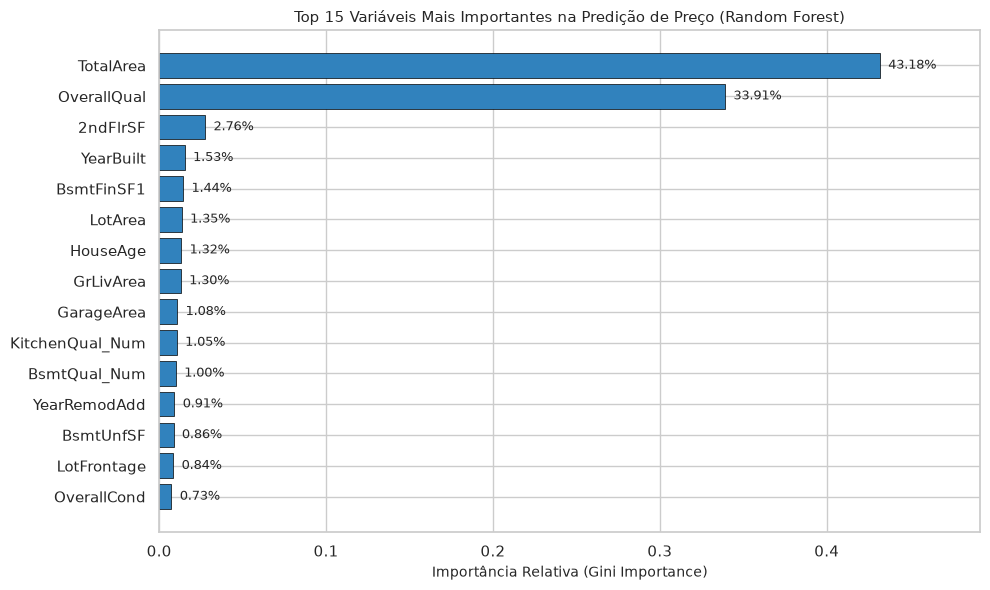

In [13]:
# Gráfico de barras horizontais do Top 15
plt.figure(figsize=(10, 6))
top_15_plot = importance_df.head(15).sort_values(by="Importance", ascending=True)
plt.barh(top_15_plot["Feature"], top_15_plot["Importance"], color="#3182bd", edgecolor="black", linewidth=0.5)
plt.xlabel("Importância Relativa (Gini Importance)")
plt.title("Top 15 Variáveis Mais Importantes na Predição de Preço (Random Forest)")
for i, v in enumerate(top_15_plot["Importance"]):
    plt.text(v + 0.005, i, f"{v*100:.2f}%", va="center", fontsize=9)
plt.xlim(0, top_15_plot["Importance"].max() + 0.06)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Preparação dos atributos contínuos para PCA
pca_features = [
    "TotalArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF",
    "GarageArea", "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1",
    "BsmtUnfSF", "HouseAge", "WoodDeckSF", "OpenPorchSF"
]

X_pca_raw = df[pca_features].copy()
X_pca_raw["LotFrontage"] = X_pca_raw["LotFrontage"].fillna(X_pca_raw["LotFrontage"].median())
X_pca_raw["MasVnrArea"] = X_pca_raw["MasVnrArea"].fillna(0)

# Padronização Z-score (média 0, desvio padrão 1)
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca_raw)

# Ajuste do PCA com 2 componentes principais
pca_model = PCA(n_components=2, random_state=42)
pca_transformed = pca_model.fit_transform(X_pca_scaled)

df["PC1"] = pca_transformed[:, 0]
df["PC2"] = pca_transformed[:, 1]

evr = pca_model.explained_variance_ratio_
print(f"Variância explicada por PC1: {evr[0] * 100:.2f}%")
print(f"Variância explicada por PC2: {evr[1] * 100:.2f}%")
print(f"Variância acumulada nos dois primeiros componentes: {evr.sum() * 100:.2f}%")

Variância explicada por PC1: 35.79%
Variância explicada por PC2: 12.53%
Variância acumulada nos dois primeiros componentes: 48.32%


## 17. Passo 16 — Dispersão dos componentes principais colorida por qualidade

Projeção bidimensional das 1.460 residências no plano PC1 vs PC2, com coloração contínua baseada na nota de `OverallQual` para verificar o padrão de agrupamento e separabilidade geométrica.

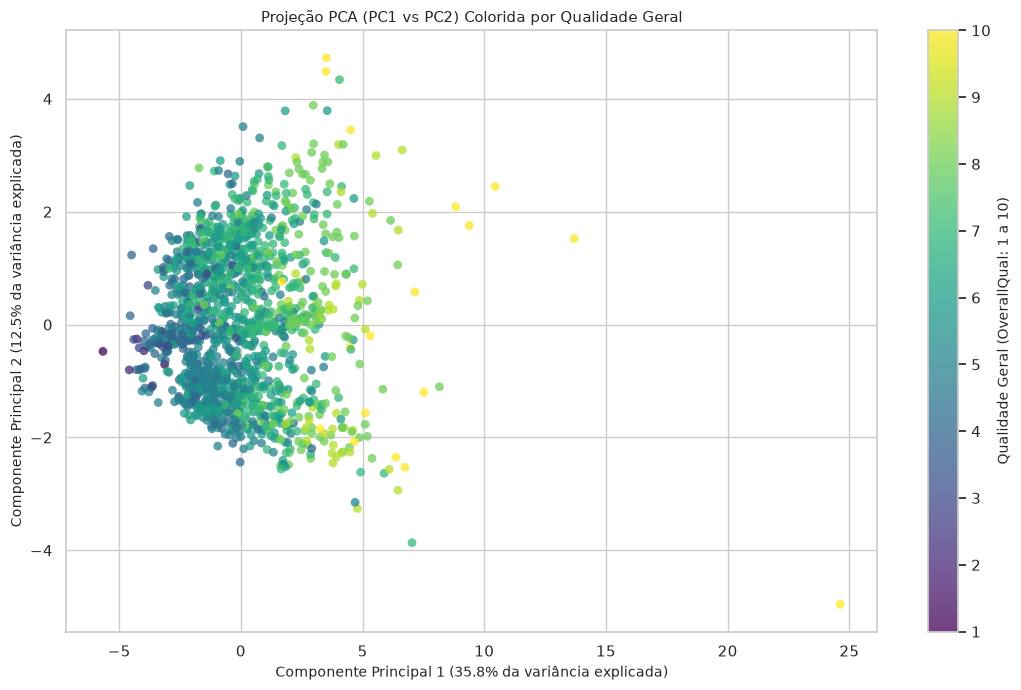

In [15]:
plt.figure(figsize=(11, 7))
scatter = plt.scatter(
    df["PC1"],
    df["PC2"],
    c=df["OverallQual"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="none",
    s=40
)
cbar = plt.colorbar(scatter)
cbar.set_label("Qualidade Geral (OverallQual: 1 a 10)", fontsize=10)
plt.title("Projeção PCA (PC1 vs PC2) Colorida por Qualidade Geral")
plt.xlabel(f"Componente Principal 1 ({evr[0]*100:.1f}% da variância explicada)")
plt.ylabel(f"Componente Principal 2 ({evr[1]*100:.1f}% da variância explicada)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_pca_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

## 18. Passo 17 — Interpretação do ranking de importância e fundamentação matemática do PCA

O ranking de importância extraído do Random Forest e a projeção por PCA fornecem leituras complementares sobre a estrutura dos dados:

1. **Desempenho dos atributos criados:** O atributo sintético `TotalArea` assume a primeira colocação absoluta no ranking de importância (~43,2% do total), superando a nota de qualidade geral (`OverallQual`, ~33,9%). Juntas, essas duas variáveis concentram mais de 77% de todo o critério de divisão da floresta. Esse resultado comprova que consolidar a área de subsolo e pavimentos em uma única grandeza física forneceu ao algoritmo um divisor muito mais eficiente do que manter as áreas fragmentadas (`GrLivArea` obteve 1,3% e `2ndFlrSF` 2,8%).

2. **Idade do imóvel e qualidades ordinais:** `HouseAge` alcança o top 10 (~1,3% de importância), demonstrando relevância superior a variáveis individuais de terreno e dormitórios. As variáveis ordinais codificadas no Passo 9 também figuram no topo: `KitchenQual_Num` (1,05%) e `BsmtQual_Num` (1,00%) confirmam que a qualidade específica de cozinha e porão direciona as divisões secundárias das árvores.

3. **Fundamentação matemática do PCA:** A Análise de Componentes Principais efetua uma decomposição espectral sobre a matriz de covariância (ou correlação) dos dados padronizados com média zero e variância unitária ($Z = \frac{X - \mu}{\sigma}$). Os autovetores dessa matriz definem direções ortogonais não correlacionadas no espaço de 14 dimensões contínuas, e os autovalores correspondentes expressam a quantidade de variância retida em cada direção. Os dois primeiros componentes concentram 48,3% da variância total do conjunto contínuo, reduzindo a complexidade de 14 para 2 dimensões sem introduzir multicolinearidade.

## 19. Passo 18 — Análise da dispersão no plano PCA

A projeção de PC1 contra PC2 exibe um gradiente contínuo de separação de qualidade:

- **Eixo horizontal (PC1):** O primeiro componente principal apresenta cargas positivas dominantes nas variáveis de metragem total (`TotalArea`, `GrLivArea`, `TotalBsmtSF`, `GarageArea`). Observa-se que imóveis de qualidade modesta (`OverallQual` 2 a 4) agrupam-se na região negativa de PC1 (médias de -4,28 e -2,00). À medida que se caminha para a direita, a coloração transita de forma coesa para tons claros: notas 6 situam-se em -0,40, notas 8 atingem +2,31 e imóveis de alto luxo (notas 9 e 10) concentram-se no extremo direito (+7,27). PC1 funciona como um índice sintético de porte e capacidade física da residência.

- **Eixo vertical (PC2):** O segundo componente principal opõe o estilo arquitetônico da residência. Ele correlaciona positivamente com área de segundo piso (`2ndFlrSF`) e negativamente com área térrea (`1stFlrSF`) e idade (`HouseAge`), discriminando sobrados de dois pavimentos de casas térreas tradicionais com subsolo amplo. A dispersão confirma que mesmo sem utilizar a variável dependente `SalePrice` no ajuste, a estrutura de covariância das áreas físicas reflete naturalmente a hierarquia de qualidade e valor das residências.

## 20. Passo 19 — Exportação do dataset de atributos processados

Exportação do conjunto de dados transformado contendo as variáveis originais, os atributos sintéticos (`HouseAge`, `TotalArea`, `IsRemodeled`), as escalas ordinais numéricas (`ExterQual_Num`, `BsmtQual_Num`, `KitchenQual_Num`), o tratamento de ausências estruturais e os eixos de projeção `PC1` e `PC2` para `data/processed/house_prices_features.csv`.

In [16]:
output_features_path = PROCESSED_DIR / "house_prices_features.csv"
df.to_csv(output_features_path, index=False)
print(f"Dataset processado exportado com sucesso em: {output_features_path}")
print(f"Dimensões finais: {df.shape[0]} linhas x {df.shape[1]} colunas")

Dataset processado exportado com sucesso em: /home/felipe/Projects/hands-on-eda/data/processed/house_prices_features.csv
Dimensões finais: 1460 linhas x 89 colunas


## 21. Passo 20 — Síntese conclusiva da engenharia de recursos e análise visual

A exploração do conjunto de dados de Ames demonstrou que transformações orientadas por conhecimento de negócio potencializam a capacidade analítica e preditiva dos dados:

- A unificação das áreas de subsolo e pavimentos superiores no atributo `TotalArea` revelou-se o fator mais determinante de preço no Random Forest, superando a influência individual de qualquer outra métrica isolada.
- O cálculo da idade efetiva no momento da transação (`HouseAge`) capturou a trajetória contínua de depreciação do imóvel de modo superior ao ano de calendário original.
- A categorização explícita de ausências estruturais (`NoPool`, `NoAlley`, `NoFence`, `NoFireplace`, `NoGarage`) impediu o descarte desnecessário de linhas e garantiu representação fidedigna do mercado imobiliário local.
- A projeção em Componentes Principais demonstrou que a estrutura de covariância entre metragens físicas e conservação organiza as residências em um gradiente natural de qualidade ao longo de PC1, validando a consistência interna das informações coletadas.

## 22. Passo 21 — Recomendações acionáveis de negócio

Com base nos resultados estatísticos e visuais obtidos, formulam-se três recomendações práticas para incorporadores, avaliadores e investidores imobiliários:

1. **Foco de reformas em cozinhas e subsolos habitáveis:** A análise de importância do Random Forest evidenciou `KitchenQual_Num` e `BsmtQual_Num` entre os atributos de maior impacto após as variáveis de área e qualidade geral. Investimentos de revitalização direcionados à modernização de armários, bancadas de cozinha e acabamento de porões proporcionam maior liquidez e retorno financeiro do que reformas estéticas externas dispersas.

2. **Precificação baseada em área útil consolidada:** Modelos de avaliação imobiliária que precificam residências utilizando apenas a metragem quadrada acima do solo (`GrLivArea`) subestimam de forma sistemática propriedades com subsolos totalmente habitáveis e acabados. A adoção de `TotalArea` reduz discrepâncias de precificação e ajusta a base de comparação entre casas térreas e sobrados.

3. **Recuperação de valor em imóveis antigos por meio de intervenções estruturais:** A comparação de preços pela variável `IsRemodeled` confirmou que residências antigas que passaram por reformas consistentes quebram o padrão usual de depreciação de `HouseAge`, alcançando patamares de negociação próximos aos de construções recentes. Investidores focados em aquisição e revitalização (house flipping) encontram o melhor custo-benefício em imóveis construídos há mais de 40 anos com estrutura preservada, mas interiores datados.

## 23. Passo 22 — Exportação das figuras em alta resolução e métricas consolidadas

Gravação das 6 figuras gráficas com resolução de 300 DPI e do arquivo de métricas em formato JSON em `reports/evidence/` para alimentar os relatórios técnicos e a suíte de testes de integridade.

In [17]:
metrics_path = EVIDENCE_DIR / "house_prices_metrics.json"

top_corr_dict = {col: round(float(val), 4) for col, val in corr_series.head(10).items()}
top_15_rf_dict = {row["Feature"]: round(float(row["Importance"]), 4) for _, row in importance_df.head(15).iterrows()}

house_prices_metrics = {
    "total_records": int(len(df)),
    "saleprice_mean": round(float(df["SalePrice"].mean()), 2),
    "saleprice_median": round(float(df["SalePrice"].median()), 2),
    "saleprice_std": round(float(df["SalePrice"].std()), 2),
    "saleprice_skew": round(float(df["SalePrice"].skew()), 4),
    "top_correlations": top_corr_dict,
    "top_15_features": top_15_rf_dict,
    "pca_explained_variance_ratio": [round(float(v), 4) for v in evr],
    "processed_shape": list(df.shape),
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(house_prices_metrics, f, indent=2, ensure_ascii=False)

print(f"Métricas exportadas com sucesso em: {metrics_path}\n")
print(json.dumps(house_prices_metrics, indent=2, ensure_ascii=False))

Métricas exportadas com sucesso em: /home/felipe/Projects/hands-on-eda/reports/evidence/house_prices_metrics.json

{
  "total_records": 1460,
  "saleprice_mean": 180921.2,
  "saleprice_median": 163000.0,
  "saleprice_std": 79442.5,
  "saleprice_skew": 1.8829,
  "top_correlations": {
    "SalePrice": 1.0,
    "OverallQual": 0.791,
    "GrLivArea": 0.7086,
    "GarageCars": 0.6404,
    "GarageArea": 0.6234,
    "TotalBsmtSF": 0.6136,
    "1stFlrSF": 0.6059,
    "FullBath": 0.5607,
    "TotRmsAbvGrd": 0.5337,
    "YearBuilt": 0.5229
  },
  "top_15_features": {
    "TotalArea": 0.4318,
    "OverallQual": 0.3391,
    "2ndFlrSF": 0.0276,
    "YearBuilt": 0.0153,
    "BsmtFinSF1": 0.0144,
    "LotArea": 0.0135,
    "HouseAge": 0.0132,
    "GrLivArea": 0.013,
    "GarageArea": 0.0108,
    "KitchenQual_Num": 0.0105,
    "BsmtQual_Num": 0.01,
    "YearRemodAdd": 0.0091,
    "BsmtUnfSF": 0.0086,
    "LotFrontage": 0.0084,
    "OverallCond": 0.0073
  },
  "pca_explained_variance_ratio": [
    0.35